# TP M1 IV — Détection de visage Réel ou Falsifié avec ACP/PCA
**Université des Sciences et de la Technologie Houari Boumediene**  
Chargée de Cours : Mme N. Laiche | Chargée de TP : Mme Y. Baroud  

---
**Pipeline :** Dataset → Prétraitement → Équilibrage → ACP → SVM → Évaluation  
**Convention :** `label 1 = Réel` | `label 0 = Fake`

## Cellule 1 — Imports et configuration générale

In [ ]:
# -*- coding: utf-8 -*-
# ============================================================
#  CELLULE 1 — Imports et configuration générale
# ============================================================

from pathlib import Path
import re
import sys
import warnings
warnings.filterwarnings('ignore')

import cv2
import joblib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import Ellipse, FancyArrowPatch
from matplotlib.gridspec import GridSpec
import numpy as np
import pandas as pd
from IPython.display import display

from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.utils import resample

# ── Paramètres globaux ────────────────────────────────────────
BASE_DIR                = Path('.').resolve()   # Dossier du notebook
DATASET_DIR             = BASE_DIR              # Dossier contenant real/ et fake/
DOSSIER_SORTIE          = BASE_DIR / 'resultats_tp_acp'
MODELE_SORTIE           = DOSSIER_SORTIE / 'modele_acp_anti_spoofing.joblib'

TAILLE_IMAGE            = (64, 64)   # Réduire si dataset très grand
UTILISER_DETECTION_VISAGE = True
N_COMPONENTS_ACP        = 0.85      # Conserver 85 % de la variance
TAILLE_TEST             = 0.25
RANDOM_STATE            = 42
FRAME_STEP_VIDEO        = 15
MAX_FRAMES_PAR_VIDEO    = 40
MAX_ECHANTILLONS_TOTAL  = None       # ex: 2000 pour limiter

EXTENSIONS_IMAGES = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff', '.webp'}
EXTENSIONS_VIDEOS = {'.avi', '.mp4', '.mov', '.mkv', '.wmv'}

MOTS_CLES_REEL = ['real', 'reel', 'réel', 'live', 'genuine', 'bonafide', 'vrai', 'normal']
MOTS_CLES_FAKE = ['fake', 'faux', 'spoof', 'attack', 'attaque', 'photo',
                  'print', 'printed', 'replay', 'screen', 'mask', 'warped', 'cut']
LABELS_TEXTE   = {0: 'Fake', 1: 'Réel'}

DOSSIER_SORTIE.mkdir(exist_ok=True)
print(f'Dossier dataset : {DATASET_DIR}')
print(f'Dossier sorties : {DOSSIER_SORTIE}')
print('Configuration OK ✓')

Dossier dataset : C:\Users\hamza\OneDrive\Bureau\projet-tp-ad
Dossier sorties : C:\Users\hamza\OneDrive\Bureau\projet-tp-ad\resultats_tp_acp
Configuration OK ✓


## Cellule 2 — Fonctions de labélisation automatique

In [2]:
# ============================================================
#  CELLULE 2 — Fonctions de labélisation automatique
# ============================================================

def nettoyer_texte(texte: str) -> str:
    """Normalise un texte pour faciliter la recherche de mots-clés."""
    for a, b in [('é','e'),('è','e'),('ê','e'),('à','a'),('_',' '),('-',' ')]:
        texte = texte.replace(a, b)
    return texte.lower()


def inferer_label_depuis_chemin(chemin: Path) -> int | None:
    """Déduit automatiquement le label à partir du chemin du fichier."""
    texte = nettoyer_texte(str(chemin))
    # Fake en priorité (plus spécifique)
    for mot in MOTS_CLES_FAKE:
        if mot in texte:
            return 0
    for mot in MOTS_CLES_REEL:
        if mot in texte:
            return 1
    # Convention CASIA numérotée
    nombres = re.findall(r'\d+', chemin.stem.lower())
    if nombres:
        n = int(nombres[-1])
        if n in {1, 2, 3}:
            return 1
        if 4 <= n <= 12:
            return 0
    return None


def lister_fichiers_dataset(dossier: Path) -> list:
    """Liste les fichiers image/vidéo avec leur label inféré."""
    extensions = EXTENSIONS_IMAGES | EXTENSIONS_VIDEOS
    refs = []
    for chemin in dossier.rglob('*'):
        if not chemin.is_file():
            continue
        if DOSSIER_SORTIE in chemin.parents:
            continue
        if chemin.suffix.lower() not in extensions:
            continue
        label = inferer_label_depuis_chemin(chemin)
        if label is not None:
            refs.append((chemin, label))
    return refs


print('Fonctions de labélisation OK ✓')

Fonctions de labélisation OK ✓


## Cellule 3 — Chargement et prétraitement des images

In [ ]:
# ============================================================
#  CELLULE 3 — Chargement et prétraitement des images
# ============================================================

def creer_detecteur_visage():
    """Charge le détecteur Haar Cascade d'OpenCV."""
    cascade_path = Path(cv2.data.haarcascades) / 'haarcascade_frontalface_default.xml'
    if not cascade_path.exists():
        return None
    det = cv2.CascadeClassifier(str(cascade_path))
    return None if det.empty() else det


def extraire_visage(image_bgr: np.ndarray, detecteur) -> np.ndarray:
    """Retourne la région du visage (avec marge) ou l'image entière."""
    if not UTILISER_DETECTION_VISAGE or detecteur is None:
        return image_bgr
    gris = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
    visages = detecteur.detectMultiScale(gris, 1.1, 5, minSize=(40, 40))
    if len(visages) == 0:
        return image_bgr
    x, y, w, h = max(visages, key=lambda b: b[2] * b[3])
    mx, my = int(0.10 * w), int(0.10 * h)
    x1, y1 = max(0, x - mx), max(0, y - my)
    x2, y2 = min(image_bgr.shape[1], x + w + mx), min(image_bgr.shape[0], y + h + my)
    return image_bgr[y1:y2, x1:x2]


def preparer_image(image_bgr: np.ndarray, detecteur) -> np.ndarray:
    """Visage → gris → redim → normalisation → vecteur 1D."""
    region = extraire_visage(image_bgr, detecteur)
    gris   = cv2.cvtColor(region, cv2.COLOR_BGR2GRAY)
    gris   = cv2.resize(gris, TAILLE_IMAGE, interpolation=cv2.INTER_AREA)
    gris   = gris.astype(np.float32) / 255.0
    return gris.flatten()


def charger_image(chemin: Path, detecteur) -> np.ndarray | None:
    img = cv2.imread(str(chemin))
    return None if img is None else preparer_image(img, detecteur)


def extraire_frames_video(chemin: Path, detecteur) -> list:
    cap = cv2.VideoCapture(str(chemin))
    if not cap.isOpened():
        return []
    vecteurs, idx = [], 0
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        if idx % FRAME_STEP_VIDEO == 0:
            vecteurs.append(preparer_image(frame, detecteur))
        if len(vecteurs) >= MAX_FRAMES_PAR_VIDEO:
            break
        idx += 1
    cap.release()
    return vecteurs


def construire_dataset(dossier: Path):
    """Construit la matrice X (vecteurs images) et le vecteur y (labels)."""
    print(' Scan du dataset...')
    detecteur = creer_detecteur_visage()
    if detecteur is None:
        print('  ⚠ Détecteur de visage indisponible — image entière utilisée.')

    refs = lister_fichiers_dataset(dossier)
    if not refs:
        raise FileNotFoundError(
            'Aucun fichier trouvé. Placez vos images dans real/ et fake/ '
            'dans le même dossier que ce notebook.'
        )

    X, y, sources = [], [], []
    for chemin, label in refs:
        if MAX_ECHANTILLONS_TOTAL and len(X) >= MAX_ECHANTILLONS_TOTAL:
            break
        ext = chemin.suffix.lower()
        if ext in EXTENSIONS_IMAGES:
            v = charger_image(chemin, detecteur)
            if v is not None:
                X.append(v); y.append(label); sources.append(str(chemin))
        elif ext in EXTENSIONS_VIDEOS:
            for i, v in enumerate(extraire_frames_video(chemin, detecteur)):
                if MAX_ECHANTILLONS_TOTAL and len(X) >= MAX_ECHANTILLONS_TOTAL:
                    break
                X.append(v); y.append(label)
                sources.append(f'{chemin}::frame_{i}')

    X = np.array(X, dtype=np.float32)
    y = np.array(y, dtype=np.int64)

    print(f'  Total échantillons : {len(X)}')
    print(f'  Dimension vecteur  : {X.shape[1]} (= {TAILLE_IMAGE[0]}×{TAILLE_IMAGE[1]} pixels)')
    print(f'  Réel  (label 1)    : {np.sum(y == 1)}')
    print(f'  Fake  (label 0)    : {np.sum(y == 0)}')

    if len(np.unique(y)) < 2:
        raise ValueError('Le dataset doit contenir au moins deux classes.')
    return X, y, sources


# ── Chargement ────────────────────────────────────────────────
X, y, sources = construire_dataset(DATASET_DIR)
print('Chargement terminé ✓')

⏳ Scan du dataset...
  Total échantillons : 8127
  Dimension vecteur  : 4096 (= 64×64 pixels)
  Réel  (label 1)    : 1991
  Fake  (label 0)    : 6136
Chargement terminé ✓


## Cellule 4 — Analyse du déséquilibre de classes et rééquilibrage

═══════════════════════════════════════════════════════
  ANALYSE DU DÉSÉQUILIBRE DE CLASSES
═══════════════════════════════════════════════════════
  Fake  :   6136 échantillons
  Réel  :   1991 échantillons
  Total :   8127 échantillons
  Ratio : 3.08
  ⚠  Dataset DÉSÉQUILIBRÉ → rééquilibrage appliqué


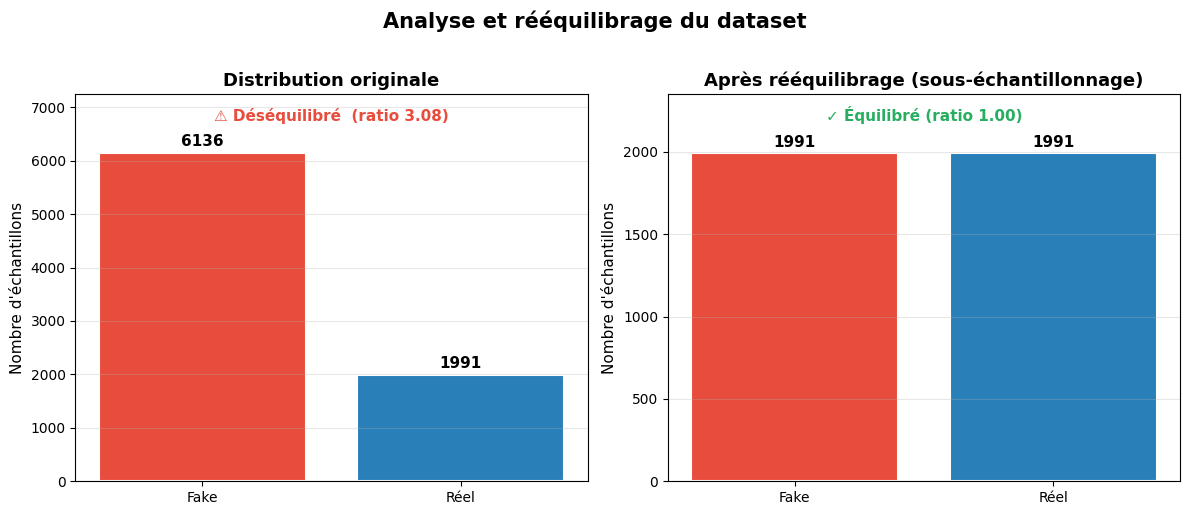

Figure sauvegardée : C:\Users\hamza\OneDrive\Bureau\projet-tp-ad\resultats_tp_acp\desequilibre_classes.png


In [ ]:
# ============================================================
#  CELLULE 4 — Analyse du déséquilibre et rééquilibrage
# ============================================================

def analyser_desequilibre(y: np.ndarray) -> dict:
    """Analyse le déséquilibre entre les deux classes."""
    n_fake = int(np.sum(y == 0))
    n_reel = int(np.sum(y == 1))
    n_total = len(y)
    ratio = max(n_fake, n_reel) / max(min(n_fake, n_reel), 1)
    desequilibre = ratio > 1.5  # déséquilibré si ratio > 1.5
    return {
        'n_fake': n_fake, 'n_reel': n_reel,
        'n_total': n_total, 'ratio': ratio,
        'desequilibre': desequilibre
    }


def equilibrer_dataset(X: np.ndarray, y: np.ndarray, random_state: int = 42):
    """
    Rééquilibre le dataset par sous-échantillonnage de la classe majoritaire.
    Retourne X_eq, y_eq équilibrés.
    """
    n_fake = np.sum(y == 0)
    n_reel = np.sum(y == 1)
    n_min  = min(n_fake, n_reel)

    idx_fake = np.where(y == 0)[0]
    idx_reel = np.where(y == 1)[0]

    rng = np.random.default_rng(random_state)
    idx_fake_eq = rng.choice(idx_fake, size=n_min, replace=False)
    idx_reel_eq = rng.choice(idx_reel, size=n_min, replace=False)

    idx_eq = np.concatenate([idx_fake_eq, idx_reel_eq])
    rng.shuffle(idx_eq)
    return X[idx_eq], y[idx_eq]


def plot_desequilibre(info: dict, y_eq: np.ndarray, ax1, ax2):
    """Deux barplots côte à côte : avant / après rééquilibrage."""
    couleurs = ['#e74c3c', '#2980b9']

    # Avant
    ax1.bar(['Fake', 'Réel'], [info['n_fake'], info['n_reel']],
            color=couleurs, edgecolor='white', linewidth=1.5)
    ax1.set_title('Distribution originale', fontsize=13, fontweight='bold')
    ax1.set_ylabel('Nombre d\'échantillons', fontsize=11)
    for i, v in enumerate([info['n_fake'], info['n_reel']]):
        ax1.text(i, v + info['n_total'] * 0.01, str(v),
                 ha='center', va='bottom', fontweight='bold', fontsize=11)
    ax1.set_ylim(0, max(info['n_fake'], info['n_reel']) * 1.18)
    etat = '⚠ Déséquilibré' if info['desequilibre'] else '✓ Équilibré'
    couleur_etat = '#e74c3c' if info['desequilibre'] else '#27ae60'
    ax1.text(0.5, 0.93, f"{etat}  (ratio {info['ratio']:.2f})",
             transform=ax1.transAxes, ha='center', color=couleur_etat,
             fontsize=11, fontweight='bold')
    ax1.grid(axis='y', alpha=0.3)

    # Après
    n_eq_fake = int(np.sum(y_eq == 0))
    n_eq_reel = int(np.sum(y_eq == 1))
    ax2.bar(['Fake', 'Réel'], [n_eq_fake, n_eq_reel],
            color=couleurs, edgecolor='white', linewidth=1.5)
    ax2.set_title('Après rééquilibrage (sous-échantillonnage)', fontsize=13, fontweight='bold')
    ax2.set_ylabel('Nombre d\'échantillons', fontsize=11)
    for i, v in enumerate([n_eq_fake, n_eq_reel]):
        ax2.text(i, v + n_eq_fake * 0.01, str(v),
                 ha='center', va='bottom', fontweight='bold', fontsize=11)
    ax2.set_ylim(0, max(n_eq_fake, n_eq_reel) * 1.18)
    ax2.text(0.5, 0.93, '✓ Équilibré (ratio 1.00)',
             transform=ax2.transAxes, ha='center', color='#27ae60',
             fontsize=11, fontweight='bold')
    ax2.grid(axis='y', alpha=0.3)


# ── Analyse ───────────────────────────────────────────────────
info_deseq = analyser_desequilibre(y)

print('═' * 55)
print('  ANALYSE DU DÉSÉQUILIBRE DE CLASSES')
print('═' * 55)
print(f'  Fake  : {info_deseq["n_fake"]:>6d} échantillons')
print(f'  Réel  : {info_deseq["n_reel"]:>6d} échantillons')
print(f'  Total : {info_deseq["n_total"]:>6d} échantillons')
print(f'  Ratio : {info_deseq["ratio"]:.2f}')
if info_deseq['desequilibre']:
    print('    Dataset DÉSÉQUILIBRÉ → rééquilibrage appliqué')
else:
    print('  ✓  Dataset équilibré')

# Rééquilibrage si nécessaire
if info_deseq['desequilibre']:
    X_eq, y_eq = equilibrer_dataset(X, y, RANDOM_STATE)
else:
    X_eq, y_eq = X.copy(), y.copy()

# Figure déséquilibre
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Analyse et rééquilibrage du dataset', fontsize=15, fontweight='bold', y=1.02)
plot_desequilibre(info_deseq, y_eq, ax1, ax2)
plt.tight_layout()
fig.savefig(DOSSIER_SORTIE / 'desequilibre_classes.png', dpi=200, bbox_inches='tight')
plt.show()
print(f'Figure sauvegardée : {DOSSIER_SORTIE / "desequilibre_classes.png"}')

## Cellule 5 — Split apprentissage / test + standardisation + ACP

In [5]:
# ============================================================
#  CELLULE 5 — Split + Standardisation + ACP exploratoire
# ============================================================

# ── Split ─────────────────────────────────────────────────────
X_train, X_test, y_train, y_test = train_test_split(
    X_eq, y_eq,
    test_size=TAILLE_TEST,
    random_state=RANDOM_STATE,
    stratify=y_eq
)
print(f'Apprentissage : {len(X_train)} échantillons')
print(f'Test          : {len(X_test)} échantillons')

# ── Standardisation ───────────────────────────────────────────
scaler  = StandardScaler()
X_std   = scaler.fit_transform(X_train)
X_test_std = scaler.transform(X_test)

# ── ACP exploratoire (toutes les composantes pour analyse) ────
acp_explore = PCA(n_components=N_COMPONENTS_ACP, svd_solver='full', random_state=RANDOM_STATE)
X_pca       = acp_explore.fit_transform(X_std)
X_test_pca  = acp_explore.transform(X_test_std)

n_comp = acp_explore.n_components_
var_pc1 = acp_explore.explained_variance_ratio_[0]
var_pc2 = acp_explore.explained_variance_ratio_[1] if n_comp > 1 else 0.0
var_tot = np.sum(acp_explore.explained_variance_ratio_)

print(f'\nComposantes ACP retenues : {n_comp}')
print(f'Variance PC1             : {var_pc1*100:.1f} %')
print(f'Variance PC2             : {var_pc2*100:.1f} %')
print(f'Variance totale conservée: {var_tot*100:.2f} %')
print('ACP calculée ✓')

Apprentissage : 2986 échantillons
Test          : 996 échantillons

Composantes ACP retenues : 37
Variance PC1             : 53.8 %
Variance PC2             : 20.1 %
Variance totale conservée: 95.06 %
ACP calculée ✓


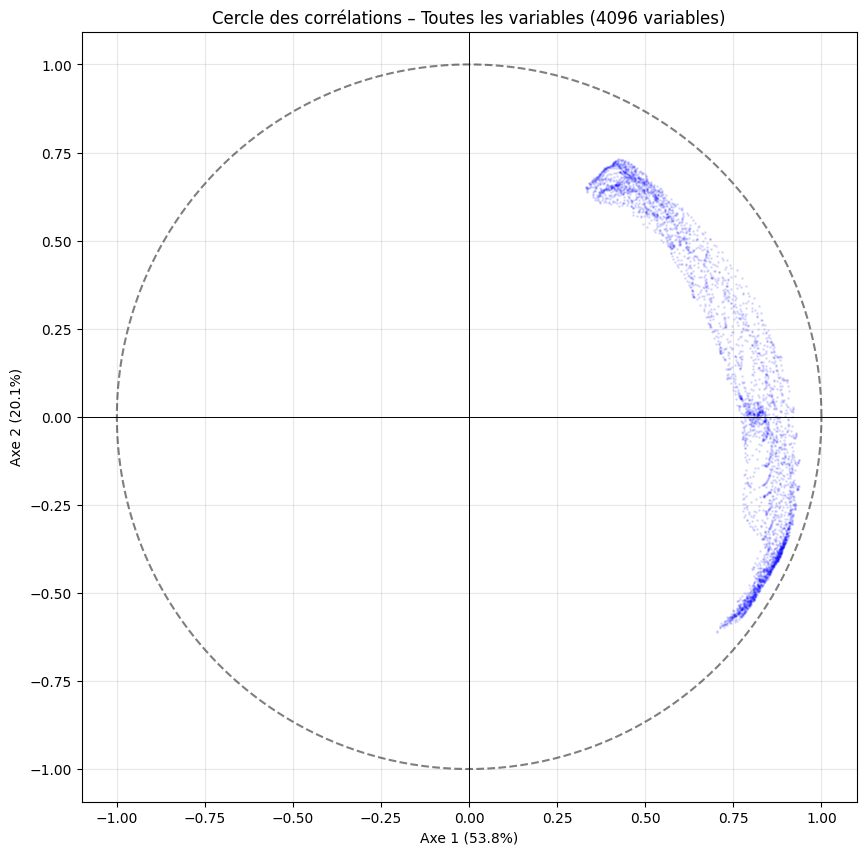

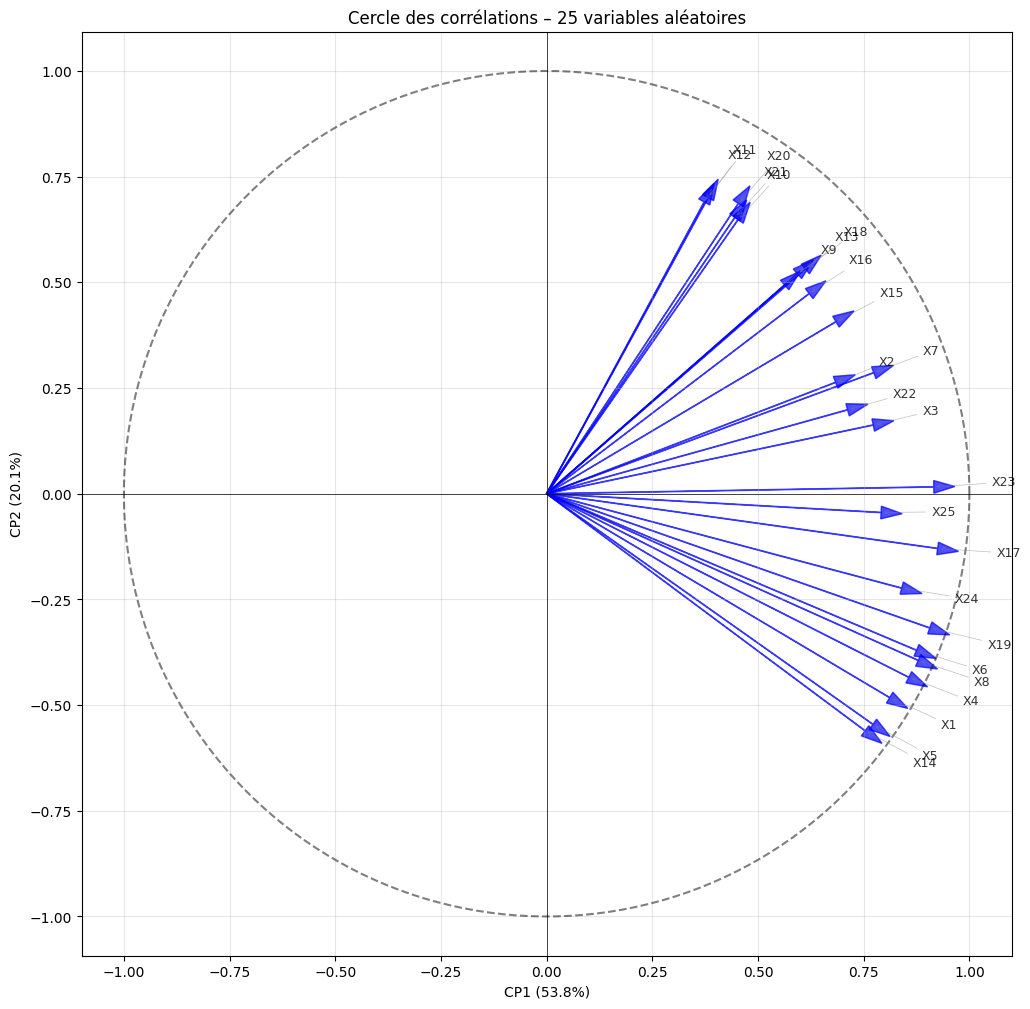

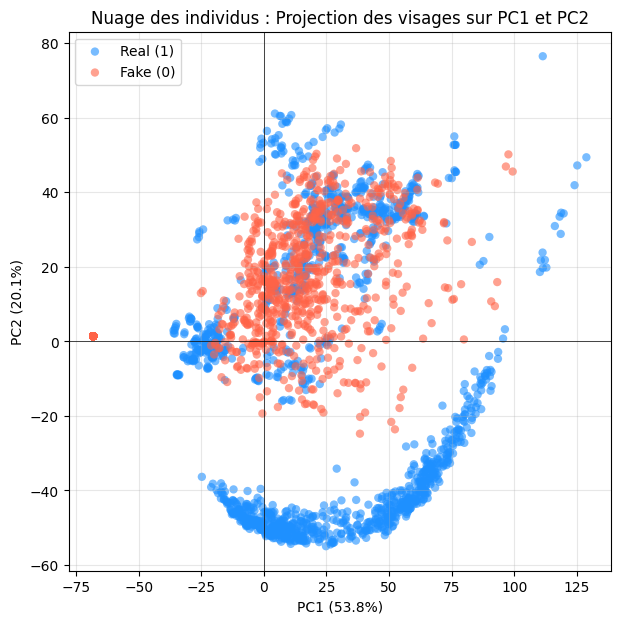

In [6]:

# ============================================================
#  CELLULE — Cercle des corrélations et projection ACP
# ============================================================

# ── Valeurs propres et variance expliquée ────────────────────
eigenvalues = acp_explore.explained_variance_
var_ratio = acp_explore.explained_variance_ratio_

# ============================================================
#  AFFICHAGE DU CERCLE DES CORRÉLATIONS – TOUTES LES VARIABLES
# ============================================================

coord1_all = np.sqrt(eigenvalues[0]) * acp_explore.components_[0, :]
coord2_all = np.sqrt(eigenvalues[1]) * acp_explore.components_[1, :]

plt.figure(figsize=(10, 10))

# Cercle unité
theta = np.linspace(0, 2 * np.pi, 200)
plt.plot(np.cos(theta), np.sin(theta), 'k--', alpha=0.5)

# Nuage de points (toutes les variables)
plt.scatter(coord1_all, coord2_all,
            alpha=0.1,
            s=1,
            c='blue')

plt.axhline(0, color='black', lw=0.7)
plt.axvline(0, color='black', lw=0.7)

plt.xlabel(f'Axe 1 ({var_ratio[0] * 100:.1f}%)')
plt.ylabel(f'Axe 2 ({var_ratio[1] * 100:.1f}%)')

plt.title(
    f'Cercle des corrélations – Toutes les variables '
    f'({len(coord1_all)} variables)'
)

plt.axis('equal')
plt.grid(alpha=0.3)
plt.show()

# ============================================================
#  CERCLE DES CORRÉLATIONS – 25 VARIABLES ALÉATOIRES
# ============================================================

np.random.seed(42)

n_vars = 25
total_vars = acp_explore.components_.shape[1]

indices_aleatoires = np.random.choice(
    total_vars,
    n_vars,
    replace=False
)

plt.figure(figsize=(12, 12))

theta = np.linspace(0, 2 * np.pi, 200)
plt.plot(np.cos(theta), np.sin(theta), 'k--', alpha=0.5)

plt.axhline(0, color='k', lw=0.5)
plt.axvline(0, color='k', lw=0.5)

for i, idx in enumerate(indices_aleatoires):

    x = coord1_all[idx]
    y = coord2_all[idx]

    plt.arrow(
        0, 0,
        x, y,
        head_width=0.03,
        head_length=0.05,
        fc='blue',
        ec='blue',
        alpha=0.7
    )

    plt.annotate(
        f'X{i+1}',
        xy=(x, y),
        xytext=(x * 1.15, y * 1.15),
        fontsize=9,
        alpha=0.8,
        arrowprops=dict(
            arrowstyle='->',
            color='gray',
            lw=0.5,
            alpha=0.5
        )
    )

plt.xlabel(f'CP1 ({var_ratio[0] * 100:.1f}%)')
plt.ylabel(f'CP2 ({var_ratio[1] * 100:.1f}%)')

plt.title('Cercle des corrélations – 25 variables aléatoires')

plt.axis('equal')
plt.grid(alpha=0.3)
plt.show()

# ============================================================
#  PROJECTION DES INDIVIDUS SUR PC1 ET PC2
# ============================================================

variance_expliquee = var_ratio * 100

plt.figure(figsize=(7, 7))

plt.axhline(0, color='black', linewidth=0.5)
plt.axvline(0, color='black', linewidth=0.5)

plt.scatter(
    X_pca[y_train == 1, 0],
    X_pca[y_train == 1, 1],
    c='dodgerblue',
    label='Real (1)',
    alpha=0.6,
    edgecolors='none'
)

plt.scatter(
    X_pca[y_train == 0, 0],
    X_pca[y_train == 0, 1],
    c='tomato',
    label='Fake (0)',
    alpha=0.6,
    edgecolors='none'
)

plt.title(
    "Nuage des individus : Projection des visages "
    "sur PC1 et PC2"
)

plt.xlabel(f"PC1 ({variance_expliquee[0]:.1f}%)")
plt.ylabel(f"PC2 ({variance_expliquee[1]:.1f}%)")

plt.legend()
plt.grid(alpha=0.3)

plt.show()


## Cellule 6 — Graphe des individus (nuage complet PC1 vs PC2)

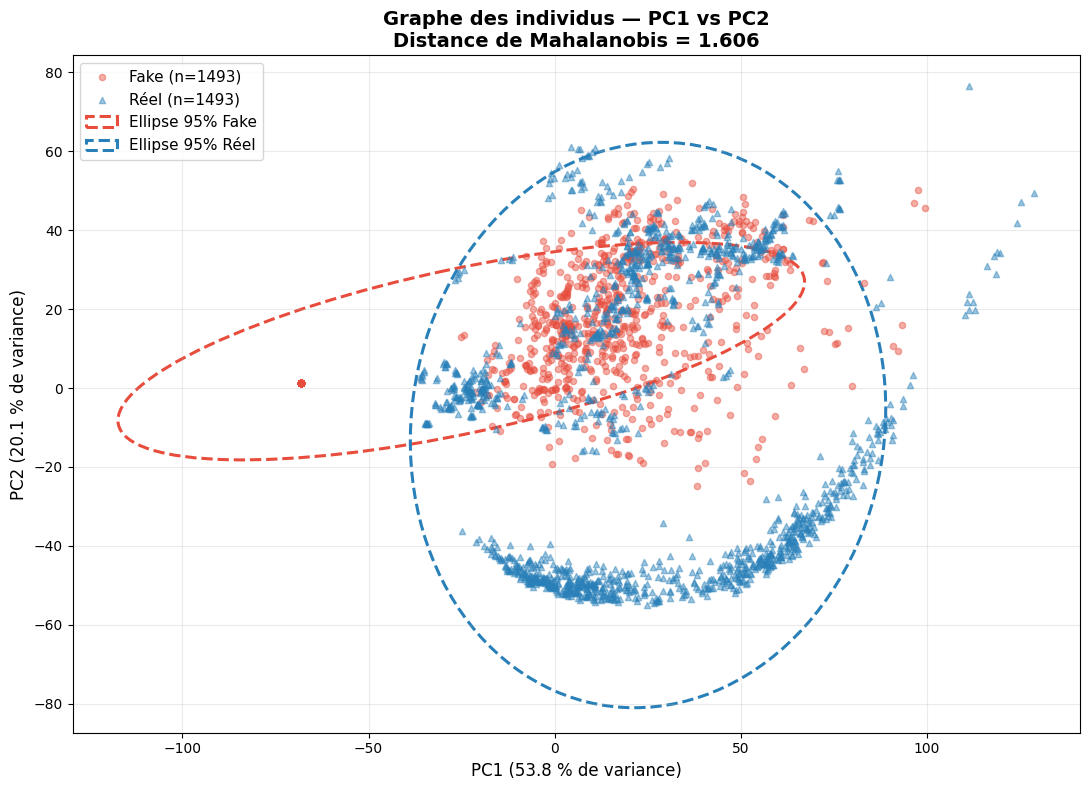

Figure sauvegardée : C:\Users\hamza\OneDrive\Bureau\projet-tp-ad\resultats_tp_acp\graphe_individus_complet.png


In [7]:
# ============================================================
#  CELLULE 6 — Nuage COMPLET des individus PC1 vs PC2
#              avec ellipses de confiance à 95 %
# ============================================================

def plot_ellipse_confiance(ax, X_2d: np.ndarray, couleur: str,
                            n_std: float = 2.0, **kwargs):
    """Dessine une ellipse de confiance à n_std σ pour un nuage 2D."""
    if len(X_2d) < 2:
        return
    mean = np.mean(X_2d, axis=0)
    cov  = np.cov(X_2d.T)
    vals, vecs = np.linalg.eigh(cov)
    ordre = vals.argsort()[::-1]
    vals, vecs = vals[ordre], vecs[:, ordre]
    angle  = np.degrees(np.arctan2(vecs[1, 0], vecs[0, 0]))
    largeur = 2 * n_std * np.sqrt(np.abs(vals[0]))
    hauteur = 2 * n_std * np.sqrt(np.abs(vals[1]))
    ell = Ellipse(xy=mean, width=largeur, height=hauteur, angle=angle,
                  fill=False, linewidth=2.2, color=couleur, **kwargs)
    ax.add_patch(ell)


COULEURS = {0: '#e74c3c', 1: '#2980b9'}
MARQUEURS = {0: 'o', 1: '^'}
NOMS    = {0: 'Fake', 1: 'Réel'}

X_fake_2d = X_pca[y_train == 0, :2]
X_reel_2d = X_pca[y_train == 1, :2]

# Distance de Mahalanobis entre les deux centres
dist_maha = 0.0
if len(X_fake_2d) >= 2 and len(X_reel_2d) >= 2:
    mf, mr = np.mean(X_fake_2d, axis=0), np.mean(X_reel_2d, axis=0)
    cf, cr = np.cov(X_fake_2d.T), np.cov(X_reel_2d.T)
    n0, n1 = len(X_fake_2d), len(X_reel_2d)
    cov_p = ((n0 - 1) * cf + (n1 - 1) * cr) / (n0 + n1 - 2)
    diff  = mr - mf
    try:
        dist_maha = float(np.sqrt(diff @ np.linalg.inv(cov_p) @ diff))
    except np.linalg.LinAlgError:
        dist_maha = 0.0

fig, ax = plt.subplots(figsize=(11, 8))

for label in [0, 1]:
    masque = y_train == label
    ax.scatter(
        X_pca[masque, 0], X_pca[masque, 1],
        c=COULEURS[label], marker=MARQUEURS[label],
        alpha=0.45, s=20, zorder=2,
        label=f"{NOMS[label]} (n={np.sum(masque)})"
    )

plot_ellipse_confiance(ax, X_fake_2d, COULEURS[0], linestyle='--', label='Ellipse 95% Fake')
plot_ellipse_confiance(ax, X_reel_2d, COULEURS[1], linestyle='--', label='Ellipse 95% Réel')

titre = (f'Graphe des individus — PC1 vs PC2\n'
         f'Distance de Mahalanobis = {dist_maha:.3f}')
ax.set_title(titre, fontsize=14, fontweight='bold')
ax.set_xlabel(f'PC1 ({var_pc1*100:.1f} % de variance)', fontsize=12)
ax.set_ylabel(f'PC2 ({var_pc2*100:.1f} % de variance)', fontsize=12)
ax.legend(loc='best', fontsize=11)
ax.grid(True, alpha=0.25)
plt.tight_layout()
fig.savefig(DOSSIER_SORTIE / 'graphe_individus_complet.png', dpi=200, bbox_inches='tight')
plt.show()
print(f'Figure sauvegardée : {DOSSIER_SORTIE / "graphe_individus_complet.png"}')

## Cellule 7 — Nuage avec sélection aléatoire de 10 variables (pixels)

Pixels sélectionnés aléatoirement : [ 351  364  385  825 1771 1795 2676 2855 3163 3513]


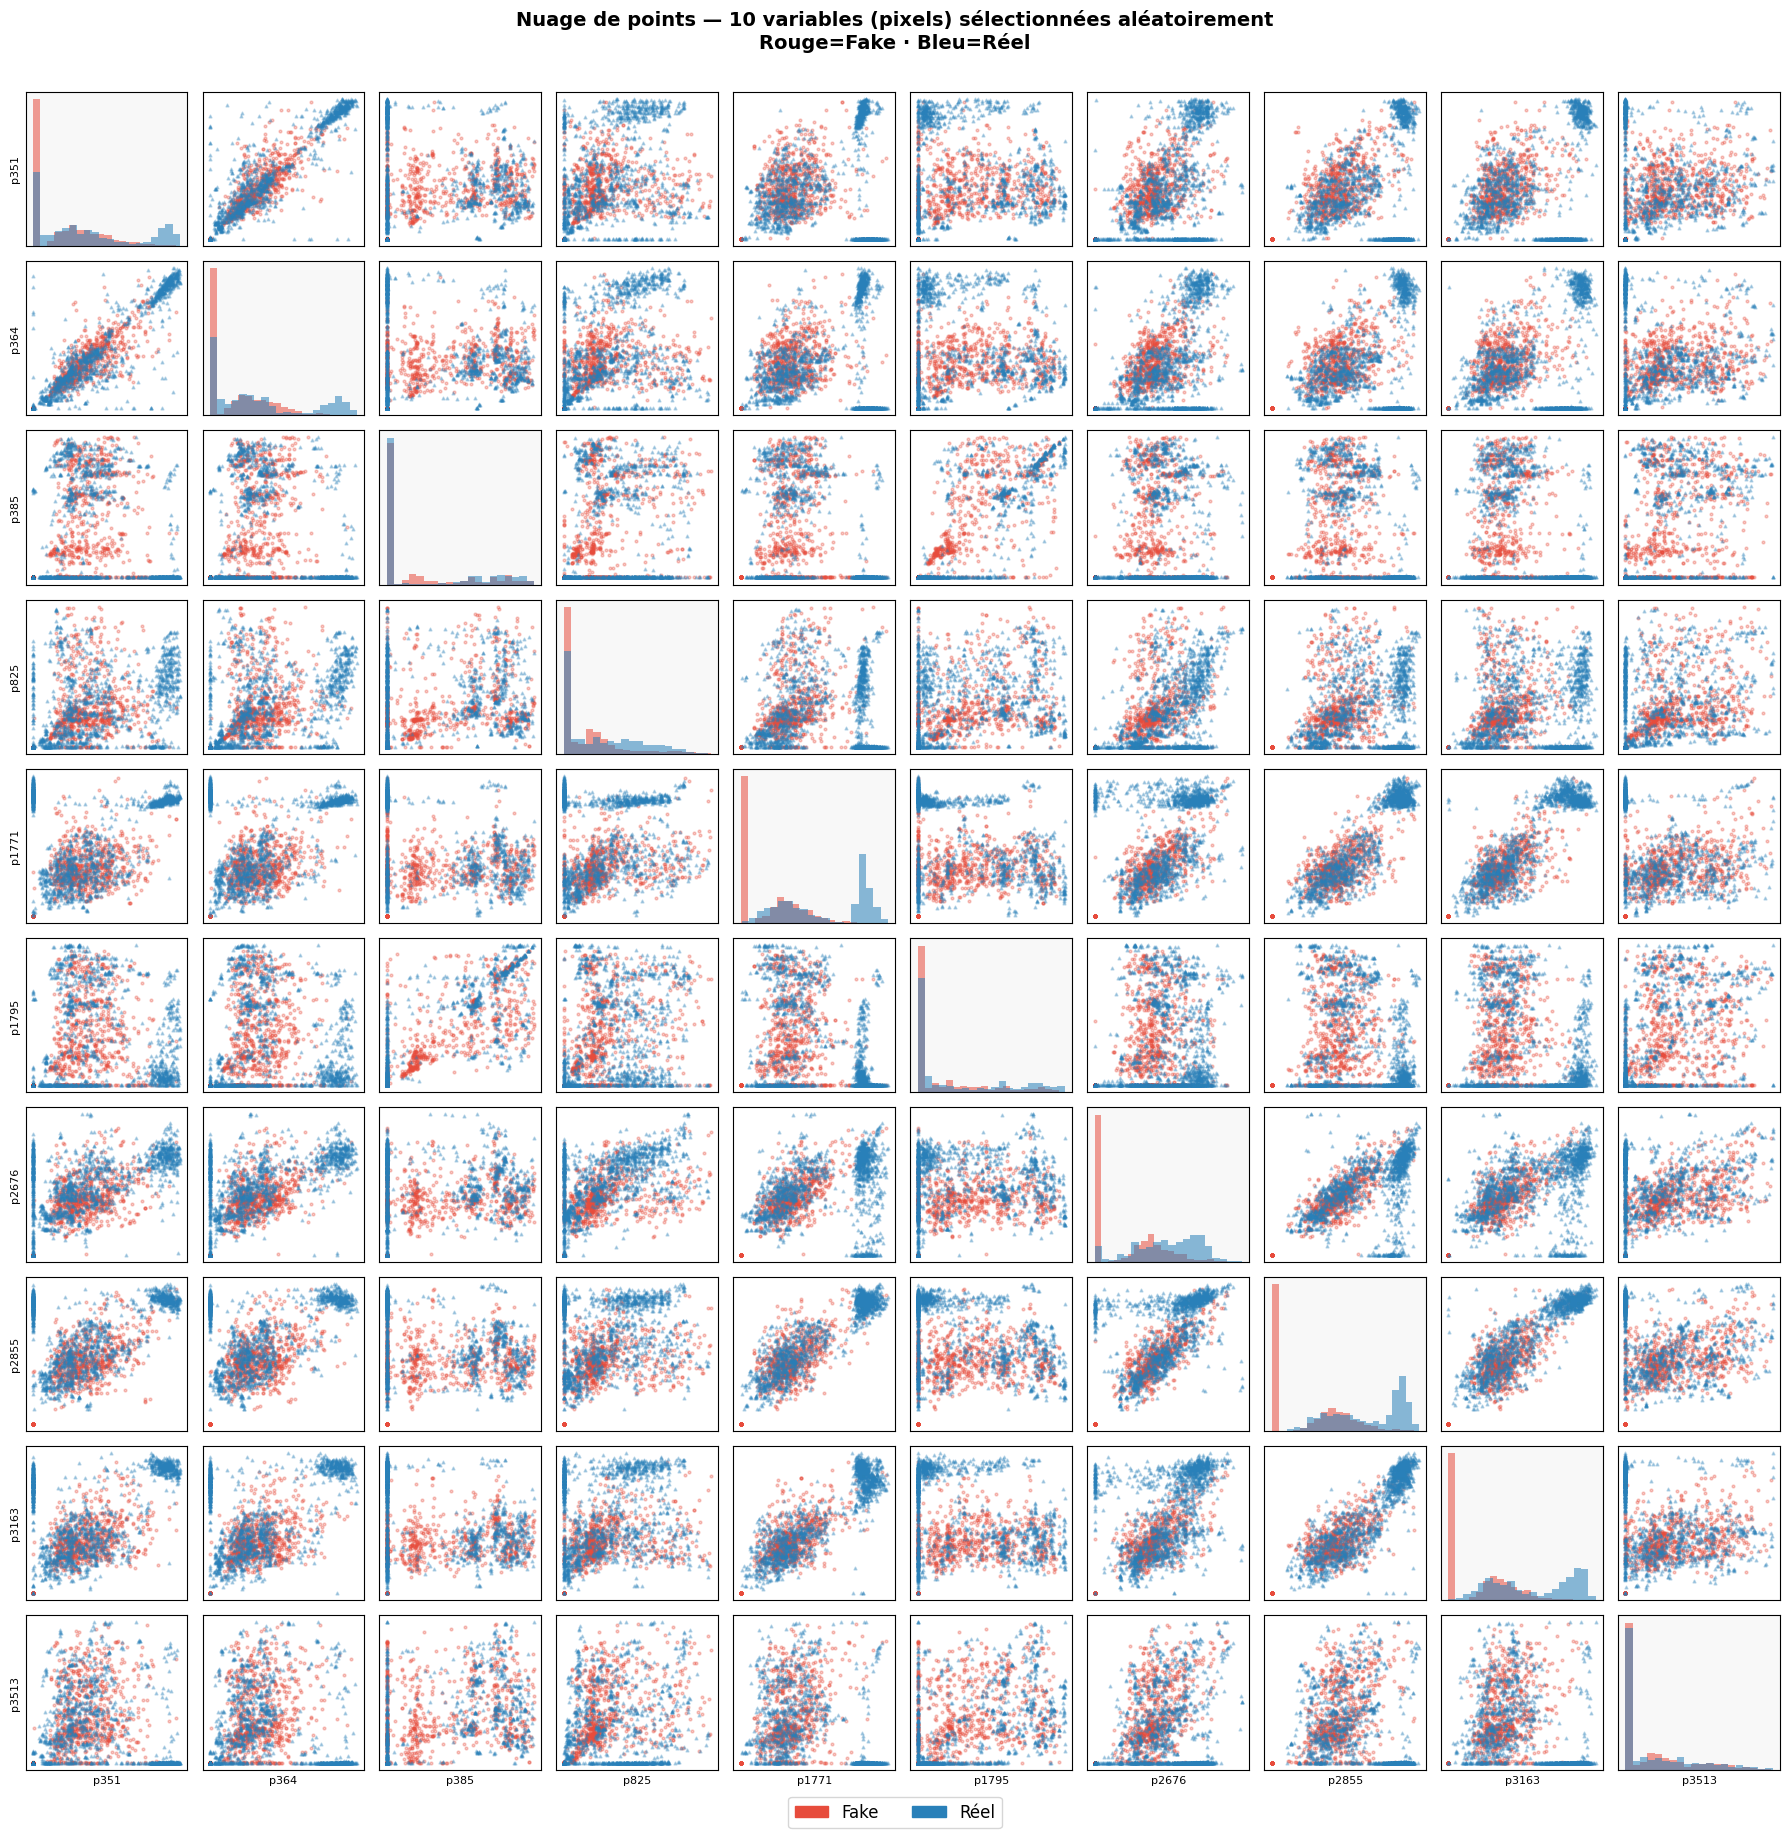

Figure sauvegardée : C:\Users\hamza\OneDrive\Bureau\projet-tp-ad\resultats_tp_acp\nuage_10_variables_aleatoires.png


In [8]:
# ============================================================
#  CELLULE 7 — Nuage avec sélection aléatoire de 10 variables
#              (scatter matrix 10 pixels × 10 pixels)
# ============================================================

rng10       = np.random.default_rng(RANDOM_STATE)
n_pixels    = X_train.shape[1]
idx_10      = np.sort(rng10.choice(n_pixels, size=10, replace=False))
X_10        = X_train[:, idx_10]               # sélection de 10 pixels
noms_vars   = [f'p{i}' for i in idx_10]

print(f'Pixels sélectionnés aléatoirement : {idx_10}')

fig, axes = plt.subplots(10, 10, figsize=(18, 18))
fig.suptitle('Nuage de points — 10 variables (pixels) sélectionnées aléatoirement\nRouge=Fake · Bleu=Réel',
             fontsize=14, fontweight='bold', y=1.005)

for i in range(10):
    for j in range(10):
        ax = axes[i, j]
        if i == j:
            # Diagonale : histogramme univarié
            ax.hist(X_10[y_train == 0, i], bins=20,
                    color=COULEURS[0], alpha=0.55, density=True)
            ax.hist(X_10[y_train == 1, i], bins=20,
                    color=COULEURS[1], alpha=0.55, density=True)
            ax.set_facecolor('#f8f8f8')
        else:
            for label in [0, 1]:
                m = y_train == label
                ax.scatter(X_10[m, j], X_10[m, i],
                           c=COULEURS[label], marker=MARQUEURS[label],
                           alpha=0.3, s=4)
        if i == 9:
            ax.set_xlabel(noms_vars[j], fontsize=8)
        if j == 0:
            ax.set_ylabel(noms_vars[i], fontsize=8)
        ax.tick_params(left=False, bottom=False,
                       labelleft=False, labelbottom=False)

# Légende
patch_fake = mpatches.Patch(color=COULEURS[0], label='Fake')
patch_reel = mpatches.Patch(color=COULEURS[1], label='Réel')
fig.legend(handles=[patch_fake, patch_reel],
           loc='lower center', ncol=2, fontsize=12,
           bbox_to_anchor=(0.5, -0.01))
plt.tight_layout(rect=[0, 0.01, 1, 1])
fig.savefig(DOSSIER_SORTIE / 'nuage_10_variables_aleatoires.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Figure sauvegardée : {DOSSIER_SORTIE / "nuage_10_variables_aleatoires.png"}')

## Cellule 8 — Cercle des corrélations avec flèches

## Cellule 9 — Eigenfaces (images propres de l'ACP)

Figure sauvegardée : C:\Users\hamza\OneDrive\Bureau\projet-tp-ad\resultats_tp_acp\eigenfaces.png


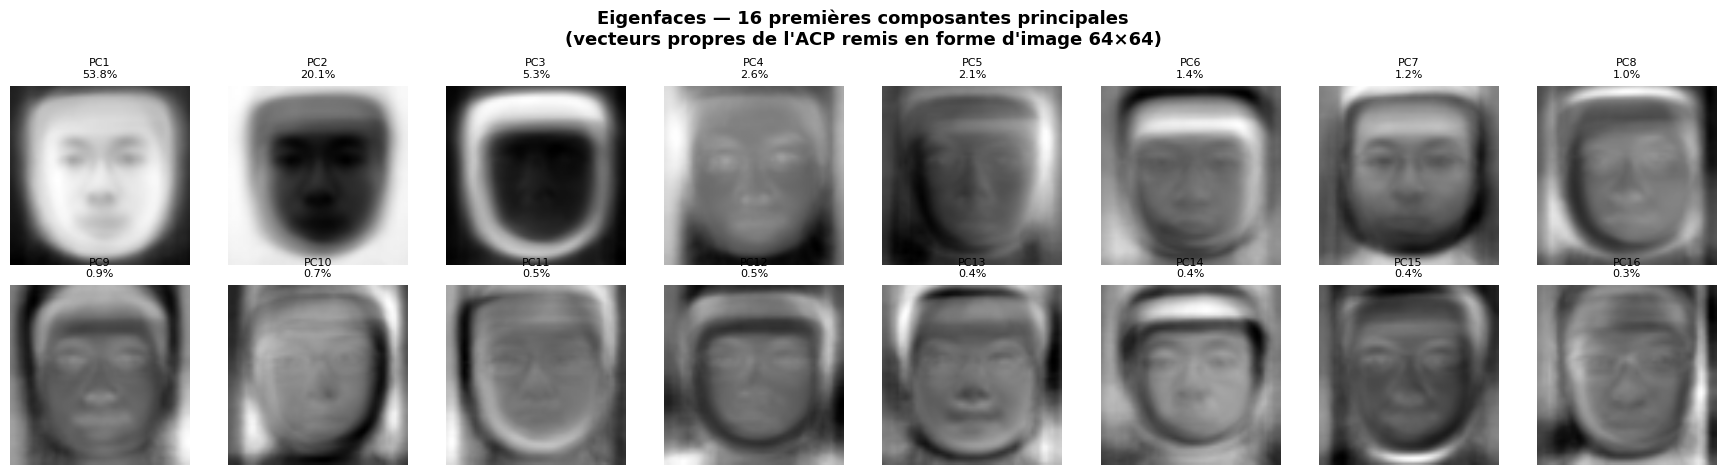

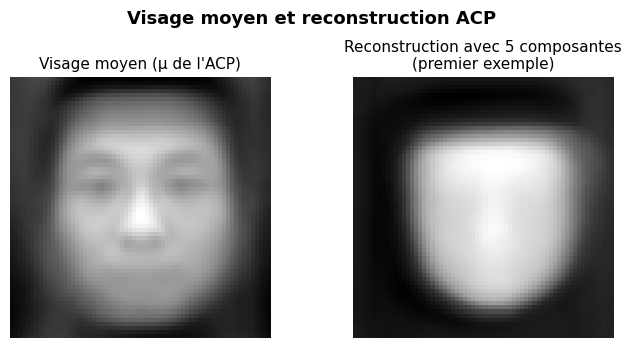

Figure sauvegardée : C:\Users\hamza\OneDrive\Bureau\projet-tp-ad\resultats_tp_acp\visage_moyen_reconstruction.png


In [10]:
# ============================================================
#  CELLULE 9 — Eigenfaces (images propres de l'ACP)
# ============================================================

def afficher_eigenfaces(
    acp, taille_image: tuple,
    n_affich: int = 16,
    chemin_sortie: Path | None = None
):
    """
    Affiche les n_affich premières eigenfaces.
    Chaque eigenface est le vecteur propre (composante principale)
    de l'ACP remis en forme d'image 2D.
    """
    n_comp_dispo = acp.n_components_
    n_affich     = min(n_affich, n_comp_dispo)
    ncols        = 8
    nrows        = int(np.ceil(n_affich / ncols))

    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 2.2, nrows * 2.4))
    fig.suptitle(
        f'Eigenfaces — {n_affich} premières composantes principales\n'
        f'(vecteurs propres de l\'ACP remis en forme d\'image {taille_image[0]}×{taille_image[1]})',
        fontsize=13, fontweight='bold'
    )

    axes_flat = axes.flatten()
    for k in range(len(axes_flat)):
        ax = axes_flat[k]
        if k < n_affich:
            eigenface = acp.components_[k].reshape(taille_image)
            # Normalisation min-max pour la visualisation
            ef_min, ef_max = eigenface.min(), eigenface.max()
            eigenface_norm = (eigenface - ef_min) / (ef_max - ef_min + 1e-9)
            ax.imshow(eigenface_norm, cmap='gray', interpolation='bilinear')
            pct = acp.explained_variance_ratio_[k] * 100
            ax.set_title(f'PC{k+1}\n{pct:.1f}%', fontsize=8)
        ax.axis('off')

    plt.tight_layout()
    if chemin_sortie:
        fig.savefig(chemin_sortie, dpi=200, bbox_inches='tight')
        print(f'Figure sauvegardée : {chemin_sortie}')
    plt.show()


afficher_eigenfaces(
    acp_explore,
    taille_image = TAILLE_IMAGE,
    n_affich     = 16,
    chemin_sortie = DOSSIER_SORTIE / 'eigenfaces.png'
)

# ── Visage moyen (mean face) ──────────────────────────────────
fig_mf, axes_mf = plt.subplots(1, 2, figsize=(7, 3.5))
mean_face = scaler.mean_.reshape(TAILLE_IMAGE)
mean_face_norm = (mean_face - mean_face.min()) / (mean_face.max() - mean_face.min() + 1e-9)

axes_mf[0].imshow(mean_face_norm, cmap='gray')
axes_mf[0].set_title('Visage moyen (μ de l\'ACP)', fontsize=11)
axes_mf[0].axis('off')

# Reconstruction avec seulement les 5 premières composantes
X_5comp = acp_explore.transform(X_std)[:, :5]
X_rec   = acp_explore.inverse_transform(
    np.concatenate([X_5comp[0:1], np.zeros((1, n_comp - 5))], axis=1)
)
rec_img = scaler.inverse_transform(X_rec)[0].reshape(TAILLE_IMAGE)
rec_norm = (rec_img - rec_img.min()) / (rec_img.max() - rec_img.min() + 1e-9)
axes_mf[1].imshow(rec_norm, cmap='gray')
axes_mf[1].set_title('Reconstruction avec 5 composantes\n(premier exemple)', fontsize=11)
axes_mf[1].axis('off')

fig_mf.suptitle('Visage moyen et reconstruction ACP', fontsize=13, fontweight='bold')
plt.tight_layout()
fig_mf.savefig(DOSSIER_SORTIE / 'visage_moyen_reconstruction.png', dpi=200, bbox_inches='tight')
plt.show()
print(f'Figure sauvegardée : {DOSSIER_SORTIE / "visage_moyen_reconstruction.png"}')

## Cellule 10 — Variance expliquée et éboulis (Scree Plot)

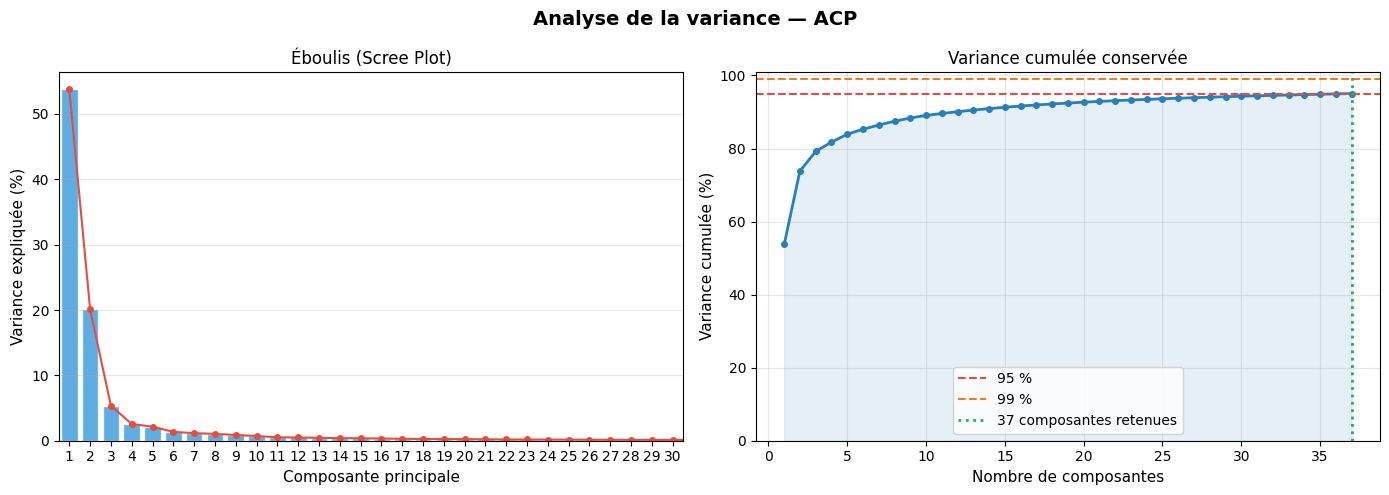

Figure sauvegardée : C:\Users\hamza\OneDrive\Bureau\projet-tp-ad\resultats_tp_acp\variance_acp.png


In [11]:
# ============================================================
#  CELLULE 10 — Variance expliquée & éboulis (Scree Plot)
# ============================================================

var_ratio = acp_explore.explained_variance_ratio_
var_cumul = np.cumsum(var_ratio)
axes_idx  = np.arange(1, n_comp + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Analyse de la variance — ACP', fontsize=14, fontweight='bold')

# ── Éboulis (Scree plot) ─────────
ax1.bar(axes_idx, var_ratio * 100, color='#3498db', alpha=0.8, edgecolor='white')
ax1.plot(axes_idx, var_ratio * 100, 'o-', color='#e74c3c', markersize=4)
ax1.set_xlabel('Composante principale', fontsize=11)
ax1.set_ylabel('Variance expliquée (%)', fontsize=11)
ax1.set_title('Éboulis (Scree Plot)', fontsize=12)
ax1.set_xlim(0.5, min(n_comp, 30) + 0.5)
ax1.set_xticks(axes_idx[:min(n_comp, 30)])
ax1.grid(axis='y', alpha=0.3)

# ── Variance cumulée ─────────────
ax2.plot(axes_idx, var_cumul * 100, 'o-', color='#2980b9',
         markersize=4, linewidth=2)
ax2.axhline(95, color='#e74c3c', linestyle='--', linewidth=1.5, label='95 %')
ax2.axhline(99, color='#e67e22', linestyle='--', linewidth=1.5, label='99 %')
# Repère du nombre de composantes retenues
ax2.axvline(n_comp, color='#27ae60', linestyle=':', linewidth=2,
            label=f'{n_comp} composantes retenues')
ax2.fill_between(axes_idx, var_cumul * 100, alpha=0.12, color='#2980b9')
ax2.set_xlabel('Nombre de composantes', fontsize=11)
ax2.set_ylabel('Variance cumulée (%)', fontsize=11)
ax2.set_title('Variance cumulée conservée', fontsize=12)
ax2.set_ylim(0, 101)
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig(DOSSIER_SORTIE / 'variance_acp.png', dpi=200, bbox_inches='tight')
plt.show()
print(f'Figure sauvegardée : {DOSSIER_SORTIE / "variance_acp.png"}')

## Cellule 11 — Top 20 variables contributives à PC1 (barplot)

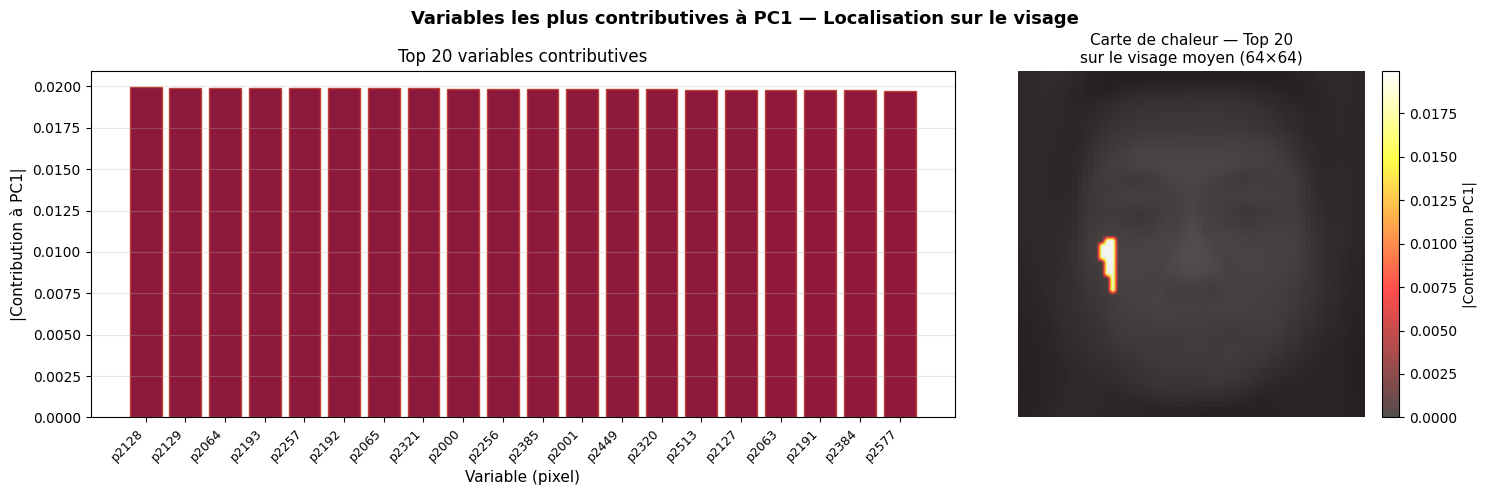

Figure sauvegardée : C:\Users\hamza\OneDrive\Bureau\projet-tp-ad\resultats_tp_acp\contributions_pc1.png


In [12]:
# ============================================================
#  CELLULE 11 — Top 20 variables contributives à PC1
# ============================================================

contrib_abs = np.abs(acp_explore.components_[0])
top20_idx   = np.argsort(contrib_abs)[::-1][:20]
top20_vals  = contrib_abs[top20_idx]
top20_labels = [f'p{i}' for i in top20_idx]

# Calcul de la position spatiale dans l'image
positions_y = top20_idx // TAILLE_IMAGE[1]   # ligne
positions_x = top20_idx  % TAILLE_IMAGE[1]   # colonne

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5),
                                gridspec_kw={'width_ratios': [2, 1]})
fig.suptitle('Variables les plus contributives à PC1 — Localisation sur le visage',
             fontsize=13, fontweight='bold')

# ── Barplot contributions ─────────
couleurs_bar = plt.cm.YlOrRd(top20_vals / top20_vals.max())
barres = ax1.bar(np.arange(20), top20_vals,
                 color=couleurs_bar, edgecolor='#c0392b', alpha=0.9)
ax1.set_xticks(np.arange(20))
ax1.set_xticklabels(top20_labels, rotation=45, ha='right', fontsize=9)
ax1.set_xlabel('Variable (pixel)', fontsize=11)
ax1.set_ylabel('|Contribution à PC1|', fontsize=11)
ax1.set_title('Top 20 variables contributives', fontsize=12)
ax1.grid(axis='y', alpha=0.3)

# ── Localisation spatiale dans l'image ───────────────────────
carte = np.zeros(TAILLE_IMAGE)
for idx, val in zip(top20_idx, top20_vals):
    iy, ix = idx // TAILLE_IMAGE[1], idx % TAILLE_IMAGE[1]
    carte[iy, ix] = val

# Fond gris + zones chaudes
ax2.imshow(scaler.mean_.reshape(TAILLE_IMAGE), cmap='gray', alpha=0.6)
im = ax2.imshow(carte, cmap='hot', alpha=0.7, interpolation='bilinear')
ax2.set_title(f'Carte de chaleur — Top 20\nsur le visage moyen ({TAILLE_IMAGE[0]}×{TAILLE_IMAGE[1]})',
              fontsize=11)
ax2.axis('off')
plt.colorbar(im, ax=ax2, fraction=0.046, pad=0.04, label='|Contribution PC1|')

plt.tight_layout()
fig.savefig(DOSSIER_SORTIE / 'contributions_pc1.png', dpi=200, bbox_inches='tight')
plt.show()
print(f'Figure sauvegardée : {DOSSIER_SORTIE / "contributions_pc1.png"}')

## Cellule 12 — Entraînement du pipeline ACP + SVM

In [13]:
# ============================================================
#  CELLULE 12 — Entraînement du pipeline ACP + SVM
# ============================================================

pipeline = Pipeline(steps=[
    ('standardisation', StandardScaler()),
    ('acp', PCA(n_components=N_COMPONENTS_ACP, svd_solver='full',
                random_state=RANDOM_STATE)),
    ('svm', SVC(kernel='rbf', C=10.0, gamma='scale',
                class_weight='balanced', random_state=RANDOM_STATE))
])

print('⏳ Entraînement StandardScaler + ACP + SVM...')
pipeline.fit(X_train, y_train)

acp_pipe = pipeline.named_steps['acp']
print(f'  Composantes ACP retenues : {acp_pipe.n_components_}')
print(f'  Variance totale conservée: {np.sum(acp_pipe.explained_variance_ratio_)*100:.2f} %')
print('Entraînement terminé ✓')

# Prédictions
y_pred = pipeline.predict(X_test)
acc    = accuracy_score(y_test, y_pred)
print(f'\nAccuracy sur le jeu de test : {acc:.4f}')

⏳ Entraînement StandardScaler + ACP + SVM...
  Composantes ACP retenues : 37
  Variance totale conservée: 95.06 %
Entraînement terminé ✓

Accuracy sur le jeu de test : 0.9829


## Cellule 13 — Évaluation complète du modèle

═══════════════════════════════════════════════════════
  RAPPORT DE CLASSIFICATION — ACP + SVM
═══════════════════════════════════════════════════════
              precision    recall  f1-score   support

        Fake       0.98      0.98      0.98       498
        Réel       0.98      0.98      0.98       498

    accuracy                           0.98       996
   macro avg       0.98      0.98      0.98       996
weighted avg       0.98      0.98      0.98       996

Accuracy GaussianNB (ACP) : 0.7831
Accuracy SVM      (ACP) : 0.9829


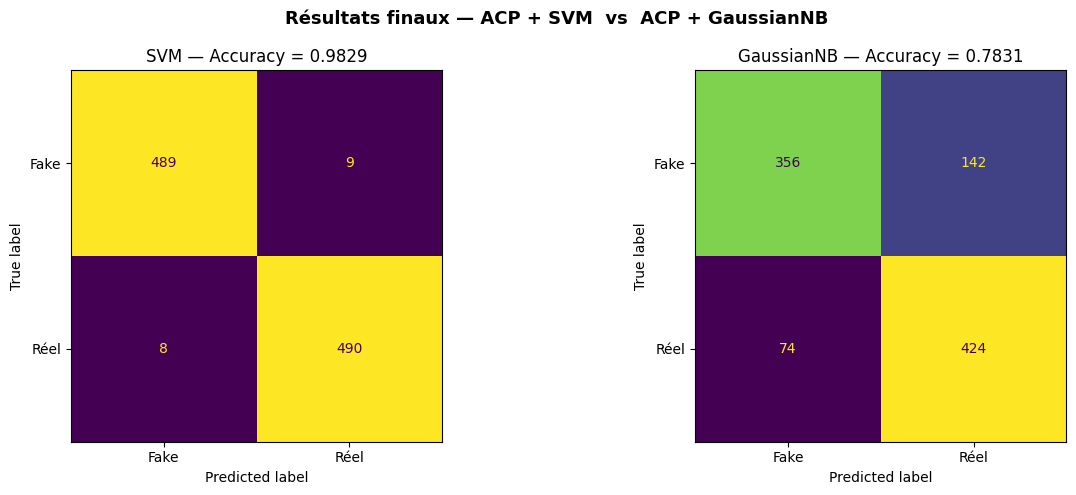

Figure sauvegardée : C:\Users\hamza\OneDrive\Bureau\projet-tp-ad\resultats_tp_acp\matrices_confusion.png


In [14]:
# ============================================================
#  CELLULE 13 — Évaluation complète
#               Rapport · Matrice de confusion · GaussianNB
# ============================================================

print('═' * 55)
print('  RAPPORT DE CLASSIFICATION — ACP + SVM')
print('═' * 55)
print(classification_report(y_test, y_pred, target_names=['Fake', 'Réel']))

# ── Comparaison avec GaussianNB ───────────────────────────────
gnb = GaussianNB()
gnb.fit(X_pca, y_train)
y_pred_gnb  = gnb.predict(X_test_pca)
acc_gnb     = accuracy_score(y_test, y_pred_gnb)
print(f'Accuracy GaussianNB (ACP) : {acc_gnb:.4f}')
print(f'Accuracy SVM      (ACP) : {acc:.4f}')

# ── Figures ───────────────────────────────────────────────────
fig, axes_ev = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Résultats finaux — ACP + SVM  vs  ACP + GaussianNB',
             fontsize=13, fontweight='bold')

# Matrice de confusion SVM
cm_svm = confusion_matrix(y_test, y_pred, labels=[0, 1])
ConfusionMatrixDisplay(cm_svm, display_labels=['Fake', 'Réel']).plot(
    values_format='d', ax=axes_ev[0], colorbar=False
)
axes_ev[0].set_title(f'SVM — Accuracy = {acc:.4f}', fontsize=12)

# Matrice de confusion GaussianNB
cm_gnb = confusion_matrix(y_test, y_pred_gnb, labels=[0, 1])
ConfusionMatrixDisplay(cm_gnb, display_labels=['Fake', 'Réel']).plot(
    values_format='d', ax=axes_ev[1], colorbar=False
)
axes_ev[1].set_title(f'GaussianNB — Accuracy = {acc_gnb:.4f}', fontsize=12)

plt.tight_layout()
fig.savefig(DOSSIER_SORTIE / 'matrices_confusion.png', dpi=200, bbox_inches='tight')
plt.show()
print(f'Figure sauvegardée : {DOSSIER_SORTIE / "matrices_confusion.png"}')

## Cellule 14 — Sauvegarde du modèle et récapitulatif

In [18]:
# ============================================================
#  CELLULE 14 — Sauvegarde du modèle et récapitulatif
# ============================================================

contenu_modele = {
    'modele'      : pipeline,
    'taille_image': TAILLE_IMAGE,
    'labels_texte': LABELS_TEXTE,
    'accuracy'    : acc,
}
joblib.dump(contenu_modele, MODELE_SORTIE)
print(f'Modèle sauvegardé : {MODELE_SORTIE}')

# ── Récapitulatif ─────────────────────────────────────────────
print('\n' + '═' * 55)
print('  RÉCAPITULATIF DU PROJET')
print('═' * 55)
print(f'  Dataset          : {DATASET_DIR}')
print(f'  Taille image     : {TAILLE_IMAGE[0]}×{TAILLE_IMAGE[1]} pixels')
print(f'  Dim. initiale    : {X_train.shape[1]} variables')
print(f'  Composantes ACP  : {acp_pipe.n_components_}')
print(f'  Variance conservée: {np.sum(acp_pipe.explained_variance_ratio_)*100:.2f} %')
print(f'  Taille train     : {len(X_train)}')
print(f'  Taille test      : {len(X_test)}')
print(f'  Accuracy SVM     : {acc:.4f}')
print(f'  Accuracy GNB     : {acc_gnb:.4f}')
print(f'  Dist. Mahalanobis: {dist_maha:.3f}')
print('═' * 55)
print()
print('Fichiers générés dans :', DOSSIER_SORTIE)
for f in sorted(DOSSIER_SORTIE.glob('*.png')):
    print(f'   {f.name}')
for f in sorted(DOSSIER_SORTIE.glob('*.joblib')):
    print(f'   {f.name}')

Modèle sauvegardé : C:\Users\hamza\OneDrive\Bureau\projet-tp-ad\resultats_tp_acp\modele_acp_anti_spoofing.joblib

═══════════════════════════════════════════════════════
  RÉCAPITULATIF DU PROJET
═══════════════════════════════════════════════════════
  Dataset          : C:\Users\hamza\OneDrive\Bureau\projet-tp-ad
  Taille image     : 64×64 pixels
  Dim. initiale    : 4096 variables
  Composantes ACP  : 37
  Variance conservée: 95.06 %
  Taille train     : 2986
  Taille test      : 996
  Accuracy SVM     : 0.9829
  Accuracy GNB     : 0.7831
  Dist. Mahalanobis: 1.606
═══════════════════════════════════════════════════════

Fichiers générés dans : C:\Users\hamza\OneDrive\Bureau\projet-tp-ad\resultats_tp_acp
   cercle_correlations.png
   cercle_correlations_10vars.png
   contributions_pc1.png
   desequilibre_classes.png
   eigenfaces.png
   graphe_individus_complet.png
   matrices_confusion.png
   nuage_10_variables_aleatoires.png
   variance_acp.png
   visage_moyen_reconstruction.png
 

## Cellule 15 — Prédiction d'une nouvelle image

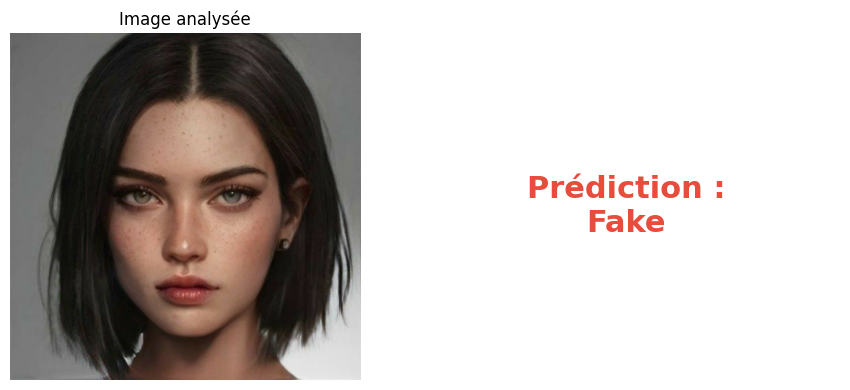

Résultat : Fake  (label 0)


In [22]:
# ============================================================
#  CELLULE 16 — Prédiction sur une image (exemple d'utilisation)
# ============================================================
# Remplacez 'chemin/vers/votre_image.jpg' par le chemin de votre image.

IMAGE_A_TESTER = 'C:/Users/hamza/OneDrive/Images/e9008abb2358585f83cac4f9a1732477.jpg'  # ← à modifier

if Path(IMAGE_A_TESTER).exists():
    predire_image(IMAGE_A_TESTER)
else:
    print(f"Fichier introuvable : {IMAGE_A_TESTER}")
    print("Vérifiez le chemin (utilisez '/' ou '\\\\' comme séparateur).")

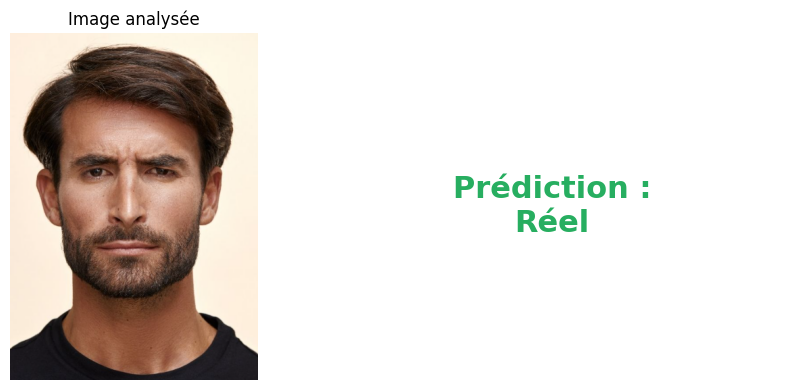

Résultat : Réel  (label 1)


In [25]:
# ============================================================
#  CELLULE 16 — Prédiction sur une image (exemple d'utilisation)
# ============================================================

IMAGE_A_TESTER = r"C:\Users\hamza\OneDrive\Images\image test reel.png"

if Path(IMAGE_A_TESTER).exists():
    predire_image(IMAGE_A_TESTER)
else:
    print(f"Fichier introuvable : {IMAGE_A_TESTER}")
    print("Vérifiez le chemin (utilisez '/' ou '\\\\' comme séparateur).")